# 02_6. Ablation by feature group and the final set / Абляция по группам признаков и итоговый набор

**EN.** Step 9 of the methodology and the summary of stage 2 (task Y1, early default; population = loans current at t, DPD = 0, never in default before t; 59 candidates, the delinquency-history features are not among them).

0. **Step-9 rule.** Starting from the features after step 8, a CatBoost model is fitted without one feature *group* at a time (borrower, loan, exposure, geography, behaviour, macro). A group is removed only if the model without it is significantly better. The rule is applied in code (section 0).
1. **Ablation of the final set.** The same comparison against the selected set: a big drop of validation AUC (ΔAUC) without a group = the group carries information the others do not have.
2. **Two references.** The model on **all 59 candidates** shows what the whole selection costs; the model on the **static set** (origination + geography) is a first look at **H3**: do dynamic features add a signal on top of static ones?
3. **Statistics** (methodology, section 8). Snapshots of one loan are dependent, so: a **cluster bootstrap by loan** (B = 1000; loans are resampled with all their snapshots) gives the 95 % CI of AUC and ΔAUC; the **DeLong test** (a standard test for the difference of two AUCs on the same loans) is run on **one random snapshot per loan**.
4. **Final table** of all 59 candidates with the decision and the reason, and `configs/features.yaml`.

Same untuned CatBoost as in 02_5 (300 trees, depth 6), full train with r = 0.2, validation without the hurricane rows (with them = sensitivity column). Validation only: **the test set is not opened**; H3 itself is tested on test in stage 3. The first run takes about 50 minutes (8 new models; the selected and all-59 models come from the 02_5 cache), later runs reuse the cache.

**RU.** Шаг 9 методологии и итог этапа 2 (задача Y1, ранний дефолт; популяция — кредиты без просрочки на t, DPD = 0, не бывшие в дефолте до t; 59 кандидатов, признаков истории просрочек среди них нет).

0. **Правило шага 9.** Начиная с признаков после шага 8, обучаем CatBoost без одной *группы* признаков (заёмщик, кредит, экспозиция, география, поведение, макро). Группа удаляется, только если модель без неё значимо лучше. Правило применяется в коде (раздел 0).
1. **Абляция итогового набора.** То же сравнение относительно отобранного набора: сильное падение AUC на validation (ΔAUC) без группы — группа несёт информацию, которой нет у остальных.
2. **Два эталона.** Модель на **всех 59 кандидатах** показывает, чего стоит весь отбор; модель на **статическом наборе** (выдача + география) — предварительный взгляд на **H3**: добавляют ли динамические признаки сигнал к статическим?
3. **Статистика** (методология, раздел 8). Снимки одного кредита зависимы, поэтому **кластерный bootstrap по кредиту** (B = 1000; кредиты перевыбираются вместе со всеми снимками) даёт 95 %-е доверительные интервалы AUC и ΔAUC, а **тест DeLong** (стандартный тест разницы двух AUC на одних и тех же кредитах) считается на **одном случайном снимке на кредит**.
4. **Итоговая таблица** по всем 59 кандидатам с решением и причиной и `configs/features.yaml`.

CatBoost тот же, что в 02_5, без подбора (300 деревьев, глубина 6), полный train с r = 0,2, validation без ураганов (с ними — колонка чувствительности). Только validation: **test не открывается**; сама H3 проверяется на test на этапе 3. Первый запуск около 50 минут (8 новых моделей; модели на отобранном наборе и на всех 59 берутся из кэша 02_5), повторные используют кэш.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import gc
import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 60)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
plt.rcParams.update({"figure.dpi": 80, "axes.grid": True, "grid.alpha": 0.3})

from xai_ews.config import feature_config
from xai_ews.data.features import COLUMNS, candidate_features, categorical_features
from xai_ews.features.data import TASKS, CategoryEncoder, load_train
from xai_ews.features.evaluation import compare_models
from xai_ews.features.importance import fit_predict_validation
from xai_ews.features.rationale import rationale_table
from xai_ews.features.redundancy import vif_from_corr
from xai_ews.features.selection import selection_table, write_features_yaml
from xai_ews.paths import FEATURE_SELECTION_DIR, STAGE2_INTERIM_DIR

CFG = feature_config()
RULES = CFG["rules"]["ablation"]
SEED = CFG["data"]["seed"]
R = lambda name: pd.read_csv(FEATURE_SELECTION_DIR / name)
uni, stab, red, imp = R("univariate.csv"), R("stability.csv"), R("redundancy.csv"), R("importance.csv")
ALL = candidate_features()
CAND = red.loc[red["pass_redundancy"], "feature"].tolist()
AFTER8 = imp.loc[imp["pass_importance"], "feature"].tolist()       # after step 8
STATIC = red.loc[red["static_h3_set"], "feature"].tolist()          # incl. original_upb and geography
STATIC_POOL = set(candidate_features(static_only=True)) | {"original_upb"}
PARAMS = CFG["rules"]["importance"]["catboost"]
print(f"tasks: {list(TASKS)}; after step 8: {len(AFTER8)}; static set: {len(STATIC)}")

tasks: ['y1']; after step 8: 21; static set: 16


### 0. Step 9 rule: drop a group that hurts / Правило шага 9: убрать мешающую группу

**EN.** Reference = the 21 features after step 8 (`after_step8`). For each feature group we fit the same CatBoost without that group. A group is removed when the model **without** it is significantly better on validation: the lower bound of the 95 % cluster-bootstrap CI of ΔAUC (without group − reference) is above 0 and DeLong p < 0.05. The rule is applied in code, not by hand.

**RU.** Эталон — 21 признак после шага 8 (`after_step8`). Для каждой группы признаков обучаем тот же CatBoost без этой группы. Группа удаляется, если модель **без** неё значимо лучше на validation: нижняя граница 95 % кластерного bootstrap-интервала ΔAUC (без группы − эталон) выше 0 и DeLong p < 0,05. Правило применяется в коде, а не вручную.

In [2]:
GROUPS8 = sorted({COLUMNS[f].group for f in AFTER8})
sets8 = {"after_step8": AFTER8, **{f"minus_{g}": [f for f in AFTER8 if COLUMNS[f].group != g] for g in GROUPS8}}
step9 = []
for task in TASKS:
    f_cache = STAGE2_INTERIM_DIR / f"ablation_step9_{task}.csv"
    if f_cache.exists() and sorted(pd.read_csv(f_cache)["model"]) == sorted(sets8):
        r = pd.read_csv(f_cache)
    else:
        p8 = {n: fit_predict_validation(task, f, PARAMS, "m_candidates" if n == "after_step8" else f"m_{n}", seed=SEED)[0]
              for n, f in sets8.items()}
        r = compare_models(p8, task, "after_step8", b=RULES["bootstrap_b"], seed=SEED)
        r["features"] = [len(sets8[n]) for n in r["model"]]
        r.to_csv(f_cache, index=False)
        del p8; gc.collect()
    step9.append(r.assign(task=task))
step9 = pd.concat(step9, ignore_index=True)
better = step9[(step9["model"] != "after_step8") & (step9["delta_lo"] > 0) & (step9["delong_p"] < 0.05)]
DROP_GROUPS = sorted(better["model"].str.removeprefix("minus_").unique())
STEP9_DROP = {f: f"without group {COLUMNS[f].group}: validation " + "; ".join(
                  f"{r.task.upper()} ΔAUC +{r.delta_auc:.4f} [{r.delta_lo:.4f}; {r.delta_hi:.4f}], DeLong p = {r.delong_p:.3f}"
                  for r in better[better["model"] == f"minus_{COLUMNS[f].group}"].itertuples())
              for f in AFTER8 if COLUMNS[f].group in DROP_GROUPS}
FINAL = [f for f in AFTER8 if f not in STEP9_DROP]
DYNAMIC = [f for f in FINAL if f not in STATIC_POOL]
H3_FULL = STATIC + DYNAMIC          # static set + selected dynamic features
GROUPS = sorted({COLUMNS[f].group for f in FINAL})
print("groups removed at step 9:", DROP_GROUPS or "none")
print(f"selected: {len(FINAL)}, selected dynamic: {len(DYNAMIC)}, H3 full: {len(H3_FULL)}, groups: {GROUPS}")
step9.set_index(["task", "model"])[["features", "auc", "delta_auc", "delta_lo", "delta_hi", "delong_p"]]

groups removed at step 9: ['geography']
selected: 18, selected dynamic: 7, H3 full: 23, groups: ['behaviour', 'borrower', 'exposure', 'loan', 'macro', 'state_at_t']


features    auc  delta_auc  delta_lo  delta_hi  delong_p
task model                                                                     
y1   after_step8             21 0.8510        NaN       NaN       NaN       NaN
     minus_behaviour         17 0.8387    -0.0123   -0.0152   -0.0094    0.0000
     minus_borrower          17 0.7732    -0.0778   -0.0854   -0.0697    0.0000
     minus_exposure          20 0.8497    -0.0013   -0.0032    0.0005    0.3374
     minus_geography         18 0.8545     0.0036    0.0015    0.0055    0.0000
     minus_loan              15 0.8488    -0.0022   -0.0047    0.0003    0.4876
     minus_macro             19 0.8497    -0.0013   -0.0032    0.0007    0.4158
     minus_state_at_t        20 0.8512     0.0002   -0.0014    0.0019    0.4926

**EN. How to read.** **The geography group (state, MSA, ZIP3) is removed by the rule**, so the selected set = the 21 features after step 8 minus these 3 = **18**. Without geography AUC is +0.0036 higher, the bootstrap CI excludes 0 ([0.0015; 0.0055]) and DeLong on one snapshot per loan confirms it (p < 0.001), so both tests of the rule are met. This agrees with step 8, where the three geography features had a permutation importance of about zero. A likely reason: CatBoost target statistics of the state, MSA and ZIP3 learn regional default levels of 2013–2015 that do not repeat later. Within the train period geography does not help either: in the within-train cross-validation (02_7, `cv_within_train.csv`) the selected set plus the whole geography group (state, MSA and ZIP3) is significantly worse than the selected set (0.855 vs 0.858, Δ −0.0026 [−0.0040; −0.0013], DeLong p < 0.001). Without borrower features (−0.078) or behaviour (−0.012) the model is much worse; without exposure (−0.0013), macro (−0.0013), loan (−0.0022) or state at t (+0.0002) the change is not significant (CI includes 0, DeLong p > 0.3), so these groups stay.

**RU. Как читать.** **Группа «география» (штат, MSA, ZIP3) удаляется по правилу**, поэтому отобранный набор = 21 признак после шага 8 минус эти 3 = **18**. Без географии AUC выше на 0,0036, интервал bootstrap не включает 0 ([0,0015; 0,0055]), и DeLong на одном снимке на кредит это подтверждает (p < 0,001), то есть выполнены оба теста правила. Это согласуется с шагом 8, где permutation importance всех трёх географических признаков был около нуля. Вероятная причина: целевые статистики штата, MSA и ZIP3 в CatBoost запоминают региональные уровни дефолтов 2013–2015 гг., которые потом не повторяются. Внутри периода train география тоже не помогает: при кросс-валидации внутри train (02_7, `cv_within_train.csv`) отобранный набор плюс вся группа «география» (штат, MSA и ZIP3) значимо хуже отобранного набора (0,855 против 0,858, Δ −0,0026 [−0,0040; −0,0013], DeLong p < 0,001). Без признаков заёмщика (−0,078) или поведения (−0,012) модель намного хуже; без экспозиции (−0,0013), макро (−0,0013), кредита (−0,0022) или состояния на t (+0,0002) изменение незначимо (интервал включает 0, DeLong p > 0,3), поэтому эти группы остаются.

### 1. Models / Модели

**EN.** The selected set, all 59, one model per dropped group, and the two H3 sets (static; static + selected dynamic). `features` = number of features in the model.

**RU.** Отобранный набор, все 59, по одной модели без каждой группы и два набора для H3 (статический; статический + отобранные динамические). `features` — число признаков в модели.

In [3]:
sets = {"selected": FINAL, "all": ALL, **({"after_step8": AFTER8} if STEP9_DROP else {}),
        **{f"minus_{g}": [f for f in FINAL if COLUMNS[f].group != g] for g in GROUPS},
        "h3_static": STATIC, "h3_full": H3_FULL}
H3_MODELS = ["h3_static", "h3_full"]
cache_name = {"selected": "m_candidates" if FINAL == AFTER8 else "m_selected", "all": "m_all",
              "after_step8": "m_candidates"}
preds = {t: {} for t in TASKS}
for task in TASKS:
    for name, feats in sets.items():
        p, _, _ = fit_predict_validation(task, feats, PARAMS,
                                         cache_name.get(name, f"m_{name}"), seed=SEED)
        preds[task][name] = p
        gc.collect()
pd.Series({n: len(f) for n, f in sets.items()}, name="features").to_frame().T

,selected,all,after_step8,minus_behaviour,minus_borrower,minus_exposure,minus_loan,minus_macro,minus_state_at_t,h3_static,h3_full
features,18,59,21,14,14,17,12,16,17,16,23


### 2. ΔAUC with cluster-bootstrap CIs and DeLong / ΔAUC с bootstrap-интервалами и DeLong

**EN.** Reference = the selected set. `delta_auc` = AUC(model) − AUC(selected); `delta_lo` / `delta_hi` — its 95 % cluster-bootstrap CI; `share_delta_le_0` — the bootstrap share of Δ ≤ 0; `delong_p` — DeLong p-value on one snapshot per loan; `auc_with_hurricanes` — the same model on validation including the hurricane rows. The counts line gives the validation sample: observations and loans, events per observation and per unique loan.

**RU.** Эталон — отобранный набор. `delta_auc` = AUC(модель) − AUC(отобранный); `delta_lo` / `delta_hi` — его 95 %-й интервал по кластерному bootstrap; `share_delta_le_0` — доля bootstrap-повторов с Δ ≤ 0; `delong_p` — p-value DeLong на одном снимке на кредит; `auc_with_hurricanes` — та же модель на validation с наблюдениями урагана. Строка counts — выборка validation: наблюдения и кредиты, события по наблюдениям и по уникальным кредитам.

In [4]:
res = {}
for task in TASKS:
    f_cache = STAGE2_INTERIM_DIR / f"ablation_{task}.csv"
    names = sorted(preds[task])
    if f_cache.exists() and sorted(pd.read_csv(f_cache)["model"]) == names and \
            pd.read_csv(f_cache)["features"].tolist() == [len(sets[n]) for n in pd.read_csv(f_cache)["model"]]:
        res[task] = pd.read_csv(f_cache)
    else:
        main_ = compare_models({n: p for n, p in preds[task].items() if n not in H3_MODELS}, task, "selected",
                               b=RULES["bootstrap_b"], seed=SEED)
        h3_ = compare_models({n: preds[task][n] for n in H3_MODELS}, task, "h3_full", b=RULES["bootstrap_b"], seed=SEED)
        print(task, "counts:", main_.attrs["counts"])
        res[task] = pd.concat([main_.assign(reference="selected"), h3_.assign(reference="h3_full")], ignore_index=True)
        res[task]["features"] = [len(sets[n]) for n in res[task]["model"]]
        res[task].to_csv(f_cache, index=False)
abl = pd.concat([r.assign(task=t) for t, r in res.items()], ignore_index=True)
abl.to_csv(FEATURE_SELECTION_DIR / "ablation.csv", index=False)
for task in TASKS:
    print(task.upper())
    display(abl[abl["task"] == task].set_index("model")[["features", "auc", "auc_lo", "auc_hi", "delta_auc", "delta_lo",
                                                          "delta_hi", "share_delta_le_0", "delong_p", "auc_with_hurricanes"]])

Y1


,features,auc,auc_lo,auc_hi,delta_auc,delta_lo,delta_hi,share_delta_le_0,delong_p,auc_with_hurricanes
model,,,,,,,,,,
selected,18,0.8538,0.8457,0.8611,NaN,NaN,NaN,NaN,NaN,0.8203
all,59,0.8509,0.8427,0.8584,-0.0029,-0.0051,-0.0010,0.9960,0.0028,0.8220
after_step8,21,0.8510,0.8432,0.8582,-0.0029,-0.0048,-0.0010,0.9980,0.0004,0.8195
minus_behaviour,14,0.8429,0.8349,0.8501,-0.0109,-0.0137,-0.0082,1.0000,0.0000,0.8143
minus_borrower,14,0.7724,0.7623,0.7826,-0.0814,-0.0893,-0.0729,1.0000,0.0000,0.7380
minus_exposure,17,0.8517,0.8438,0.8590,-0.0021,-0.0044,0.0001,0.9700,0.0355,0.8181
minus_loan,12,0.8505,0.8425,0.8579,-0.0033,-0.0055,-0.0011,0.9990,0.0000,0.8183
minus_macro,16,0.8514,0.8437,0.8589,-0.0024,-0.0048,-0.0003,0.9840,0.0060,0.8169
minus_state_at_t,17,0.8539,0.8457,0.8612,0.0001,-0.0019,0.0020,0.4590,0.7532,0.8212


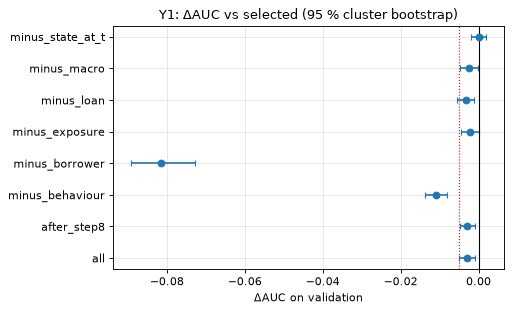

In [5]:
fig, axes = plt.subplots(1, len(TASKS), figsize=(5.5 * len(TASKS) + 1, 4), sharey=True, squeeze=False)
order = [n for n in ["all", "after_step8", *[f"minus_{g}" for g in GROUPS]] if n in sets]
for ax, task in zip(axes[0], TASKS):
    d = abl[(abl["task"] == task) & (abl["reference"] == "selected")].set_index("model").reindex(order)
    yy = np.arange(len(d))
    ax.errorbar(d["delta_auc"], yy, xerr=[d["delta_auc"] - d["delta_lo"], d["delta_hi"] - d["delta_auc"]],
                fmt="o", capsize=3)
    ax.axvline(0, c="k", lw=1); ax.axvline(-RULES["non_inferiority_auc"], c="r", ls=":", lw=1)
    ax.set_yticks(yy, order); ax.set_title(f"{task.upper()}: ΔAUC vs selected (95 % cluster bootstrap)")
    ax.set_xlabel("ΔAUC on validation")
plt.tight_layout(); plt.show()

**EN. How to read.** Reference = the selected set of 18. Each row: ΔAUC vs the selected set with its 95 % cluster-bootstrap CI (by loan; 610,679 loans and 2,259 event loans; 1,854,380 observations with 3,706 events). DeLong uses one random snapshot per loan (610,679 rows, 1,763 events) and has less power than the bootstrap.
- **Borrower** features carry the most unique information (−0.081), then **behaviour** (−0.011). Without the delinquency history, the credit quality at origination is the main source of the signal, and the payment pace and partial prepayments are the main dynamic one.
- **Loan** (−0.0033) and **macro** (−0.0024) add a small but real signal: both CIs exclude 0, DeLong p ≤ 0.006. **Exposure** (−0.0021) is borderline: CI [−0.0044; 0.0001] just includes 0, DeLong p = 0.04.
- **State at t** (`age`): +0.0001, CI [−0.0019; 0.0020] includes 0, DeLong p = 0.75. On validation loan age adds nothing beyond the other groups; it is not harmful, so by the step-9 rule it stays.
- **Geography** was removed at step 9 (section 0): the 21 features after step 8, i.e. the selected set plus geography, are 0.0029 lower [−0.0048; −0.0010].
- With the hurricane rows (last column) the order of the group drops is the same, but all 59 and the set with geography come out about level with the selected set (0.822 and 0.820 vs 0.820): with these rows the state-level features "predict" the hurricane (02_2).

**RU. Как читать.** Эталон — отобранный набор из 18 признаков. В каждой строке ΔAUC относительно него с 95 %-м интервалом кластерного bootstrap (по кредиту; 610 679 кредитов и 2 259 кредитов с событием; 1 854 380 наблюдений и 3 706 событий). DeLong считается на одном случайном снимке на кредит (610 679 строк, 1 763 события), и мощность у него меньше, чем у bootstrap.
- Больше всего уникальной информации у признаков **заёмщика** (−0,081), затем у **поведения** (−0,011). Без истории просрочек главный источник сигнала — качество заёмщика при выдаче, а главный динамический — темп погашения и частичные досрочные погашения.
- **Кредит** (−0,0033) и **макро** (−0,0024) добавляют небольшой, но реальный сигнал: оба интервала не включают 0, DeLong p ≤ 0,006. **Экспозиция** (−0,0021) — пограничный случай: интервал [−0,0044; 0,0001] чуть задевает 0, DeLong p = 0,04.
- **Состояние на t** (`age`): +0,0001, интервал [−0,0019; 0,0020] включает 0, DeLong p = 0,75. На validation возраст кредита ничего не добавляет к остальным группам; он не вредит, поэтому по правилу шага 9 остаётся.
- **География** удалена на шаге 9 (раздел 0): 21 признак после шага 8, то есть отобранный набор плюс география, даёт AUC ниже на 0,0029 [−0,0048; −0,0010].
- С наблюдениями урагана (последняя колонка) порядок групп тот же, но все 59 и набор с географией оказываются примерно на уровне отобранного (0,822 и 0,820 против 0,820): на этих строках признаки уровня штата «угадывают» ураган (02_2).

### 3. Non-inferiority of the selected set / Не хуже ли отобранный набор

**EN.** Rule fixed in advance: the selected set may lose at most 0.005 validation AUC against all 59 candidates. We require the **upper** end of the 95 % CI of ΔAUC(all − selected) to be below 0.005, i.e. we are 95 % sure the loss is smaller than the margin.

**RU.** Правило зафиксировано заранее: отобранный набор может уступать всем 59 кандидатам не больше 0,005 AUC на validation. Требуем, чтобы **верхняя** граница 95 %-го интервала ΔAUC(все − отобранный) была ниже 0,005, то есть с уверенностью 95 % потеря меньше допуска.

In [6]:
ni = abl[(abl["model"] == "all")][["task", "features", "auc", "delta_auc", "delta_lo", "delta_hi", "delong_p"]].copy()
ni["auc_selected"] = ni["auc"] - ni["delta_auc"]
ni["non_inferior"] = ni["delta_hi"] < RULES["non_inferiority_auc"]
ni.rename(columns={"auc": "auc_all", "delta_auc": "gain_of_all"})

,task,features,auc_all,gain_of_all,delta_lo,delta_hi,delong_p,auc_selected,non_inferior
1,y1,59,0.8509,-0.0029,-0.0051,-0.0010,0.0028,0.8538,True


**EN. Conclusion.** The selected set of 18 is **not worse** than all 59 candidates on validation — it is even slightly better: ΔAUC(all − selected) = −0.0029 [−0.0051; −0.0010], DeLong p = 0.003; the upper bound is well below +0.005, so the non-inferiority rule is met. The 41 excluded features add nothing. AUC of the selected set: **0.854** [0.846; 0.861]; with the hurricane rows 0.820. The level is lower than in the earlier version of this stage (about 0.93) because the population now contains only loans that are current at t and have never been in default before t, and the delinquency-history features are excluded: the model no longer sees a delinquency that has already started and has to warn before the first missed payment. This is a harder task, but it is the actual early-warning task.

**RU. Вывод.** Отобранный набор из 18 признаков **не хуже** всех 59 кандидатов на validation — он даже немного лучше: ΔAUC(все − отобранный) = −0,0029 [−0,0051; −0,0010], DeLong p = 0,003; верхняя граница намного ниже +0,005, так что правило «не хуже» выполнено. 41 исключённый признак ничего не добавляет. AUC отобранного набора: **0,854** [0,846; 0,861]; с наблюдениями урагана — 0,820. Уровень ниже, чем в прежней версии этого этапа (около 0,93), потому что теперь в популяции только кредиты без просрочки на t, ни разу не бывшие в дефолте до t, а признаки истории просрочек исключены: модель больше не видит уже начавшуюся просрочку и должна предупреждать до первого пропущенного платежа. Задача сложнее, но именно это и есть задача раннего предупреждения.

### 4. First look at H3: static set vs static + dynamic / Предварительный взгляд на H3: статический набор против статического + динамического

**EN.** H3: hidden deterioration is visible in advance — for early default (Y1), dynamic features (behaviour, macro) add a significant signal on top of the static ones. The "full" model = the static set (selected separately among static features) + the selected dynamic features, so the difference measures only what the dynamic features add. Here only the validation preview of the AUC part; the decision on H3 (ΔAUC > 0 with DeLong p < 0.05 **and** median lead time ≥ 3 months) is made on test in stage 3.

**RU.** H3: скрытое ухудшение видно заранее — для раннего дефолта (Y1) динамические признаки (поведение, макро) добавляют значимый сигнал к статическим. «Полная» модель = статический набор (отобран отдельно среди статических) + отобранные динамические признаки, поэтому разница измеряет только вклад динамики. Здесь — только предварительный взгляд на часть про AUC на validation; решение по H3 (ΔAUC > 0 при p DeLong < 0,05 **и** медианный lead time ≥ 3 мес.) принимается на test на этапе 3.

In [7]:
h3 = abl[abl["model"] == "h3_static"][["task", "features", "auc", "delta_auc", "delta_lo", "delta_hi", "delong_p"]].copy()
h3["auc_full"] = h3["auc"] - h3["delta_auc"]
h3["gain_of_dynamic"] = -h3["delta_auc"]
h3["gain_ci"] = [f"[{-hi:.4f}, {-lo:.4f}]" for lo, hi in zip(h3["delta_lo"], h3["delta_hi"])]
h3.rename(columns={"auc": "auc_static"})[["task", "features", "auc_static", "auc_full", "gain_of_dynamic", "gain_ci", "delong_p"]]

,task,features,auc_static,auc_full,gain_of_dynamic,gain_ci,delong_p
9,y1,16,0.8362,0.8495,0.0134,"[0.0101, 0.0166]",0.0000


**EN. How to read and conclusion.** Static set = 16 features (origination data incl. `original_upb`, state, MSA and ZIP3; besides the 11 static features of the selected set it keeps the three geography features, removed from the main set at step 9, and the original loan term and the original LTV, which in the main set are replaced by their dynamic twins); full = static + 7 selected dynamic features = 23. Static 0.836, full 0.850: **+0.013 [0.010; 0.017]**, DeLong p < 0.0001 on one snapshot per loan. The AUC part of H3 is supported on validation: even among loans that are paying on time, what happens with the loan *after* origination (payment pace against the schedule, partial prepayments, current LTV, local house prices, loan age) separates future defaults better than the origination data alone. The gain is smaller than in the earlier version of this stage (+0.076) because the delinquency history is no longer part of the dynamic set; what is left is a signal that comes before any missed payment. Caveats: this is validation, not test, and H3 also requires the median lead time ≥ 3 months — both are checked in stage 3.

**RU. Как читать и вывод.** Статический набор — 16 признаков (данные при выдаче, включая `original_upb`, штат, MSA и ZIP3; кроме 11 статических признаков отобранного набора в нём остаются три географических признака, удалённые из основного набора на шаге 9, а также срок кредита и LTV при выдаче, которые в основном наборе заменены динамическими двойниками); полный — статический + 7 отобранных динамических = 23. Статический 0,836, полный 0,850: **+0,013 [0,010; 0,017]**, DeLong p < 0,0001 на одном снимке на кредит. Часть H3 про AUC на validation подтверждается: даже среди кредитов, которые платят вовремя, то, что происходит с кредитом *после* выдачи (темп погашения относительно графика, частичные досрочные погашения, текущий LTV, местные цены на жильё, возраст кредита), отделяет будущие дефолты лучше, чем одни данные при выдаче. Прирост меньше, чем в прежней версии этого этапа (+0,076), потому что история просрочек больше не входит в динамические признаки; остаётся сигнал, который появляется раньше любого пропущенного платежа. Оговорки: это validation, а не test, и для H3 нужен ещё медианный lead time ≥ 3 мес. — обе вещи проверяются на этапе 3.

### 5. Final selection table / Итоговая таблица отбора

**EN.** All 59 candidates: expected and observed sign, IV and KS (train / validation), PSI, VIF in the final set, SHAP share, Boruta, decision and reason (the first step the feature failed). The 10 delinquency-history features are not candidates and are not in the table. Saved to `reports/feature_selection/feature_selection_table.csv` (thesis appendix). Shown here in a compact form.

**RU.** Все 59 кандидатов: ожидаемый и фактический знак, IV и KS (train / validation), PSI, VIF в итоговом наборе, доля SHAP, Boruta, решение и причина (первый шаг, который признак не прошёл). 10 признаков истории просрочек не являются кандидатами и в таблицу не входят. Сохраняется в `reports/feature_selection/feature_selection_table.csv` (приложение диссертации). Здесь — в сжатом виде.

In [8]:
vif_final = {}
for task in TASKS:
    c = pd.read_csv(STAGE2_INTERIM_DIR / f"woe_corr_{task}.csv", index_col=0)
    fs = [f for f in FINAL if f in c.index]
    vif_final[task] = pd.Series(vif_from_corr(c.loc[fs, fs].to_numpy()), index=fs)
vif_final = pd.DataFrame(vif_final)
table = selection_table(rationale_table(), uni, stab, red, imp, vif_final, ablation_drop=STEP9_DROP)
table.to_csv(FEATURE_SELECTION_DIR / "feature_selection_table.csv", index=False)
compact = table.assign(feature=table["feature"].str.slice(0, 40))[
    ["feature", "group", "expected_sign", *[f"{c}_{t}" for c in ("direction_train", "iv_train", "ks_train") for t in TASKS],
     "psi_max", *[f"vif_final_{t}" for t in TASKS], "decision", "dropped_at_step"]]
with pd.option_context("display.max_rows", 80):
    display(compact.sort_values(["decision", "dropped_at_step", "group"], ascending=[False, True, True]).set_index("feature"))

,group,expected_sign,direction_train_y1,iv_train_y1,ks_train_y1,psi_max,vif_final_y1,decision,dropped_at_step
feature,,,,,,,,,
upb_vs_schedule,behaviour,+,0.0895,0.2026,0.1564,0.0104,2.0775,keep,
n_curtail_6m,behaviour,-,-0.0137,0.2128,0.1252,0.0009,1.3986,keep,
upb_chg_6m,behaviour,+,0.1606,0.3501,0.2228,0.1029,2.6614,keep,
excess_principal_12m,behaviour,-,-0.0178,0.1682,0.1436,0.0059,1.6784,keep,
borrower_credit_score_at_origination,borrower,-,-0.2866,1.1799,0.4466,0.0355,1.2914,keep,
co_borrower_credit_score_at_origination,borrower,-,-0.2944,0.9260,0.3744,0.0298,1.2588,keep,
debt_to_income_dti,borrower,+,0.1496,0.3156,0.2281,0.0206,1.1270,keep,
first_time_home_buyer_indicator,borrower,cat,NaN,0.0494,0.0814,0.0268,1.2473,keep,
original_upb,exposure,none,-0.0840,0.1019,0.1302,0.0038,1.1861,keep,


In [9]:
funnel = [("candidates", len(table))]
left = len(table)
for step in ["2 univariate", "6 stability", "7 sign", "4-5 redundancy", "8 importance", "9 ablation"]:
    left -= (table["dropped_at_step"] == step).sum()
    funnel.append((f"after step {step}", left))
pd.DataFrame(funnel, columns=["stage", "features"]).set_index("stage").T

stage,candidates,after step 2 univariate,after step 6 stability,after step 7 sign,after step 4-5 redundancy,after step 8 importance,after step 9 ablation
features,59,43,36,36,21,21,18


In [10]:
print("selected by group:")
table[table["decision"] == "keep"].groupby("group")["feature"].apply(lambda s: ", ".join(s)).to_frame()

selected by group:


,feature
group,
behaviour,"upb_vs_schedule, n_curtail_6m, upb_chg_6m, excess_princi..."
borrower,"borrower_credit_score_at_origination, co_borrower_credit..."
exposure,original_upb
loan,"original_interest_rate, loan_purpose, seller_name, prope..."
macro,"mtm_ltv, hpi_chg_since_orig_rel_us"
state_at_t,age


**EN. Conclusion.** Funnel: **59 → 43** (step 2, IV) **→ 36** (step 6, stability) **→ 36** (step 7, sign) **→ 21** (steps 4–5, redundancy) **→ 21** (step 8, importance) **→ 18** (step 9, ablation: the geography group). 41 features are excluded, each with the first step it failed and the reason. In the final set the largest VIF is 2.7 (`upb_chg_6m`); all PSI values are at most 0.10 except `seller_name` (0.24) and `age` (0.21), both below the 0.25 limit, and the two macro features also passed the check of a stable relationship across years. By group: borrower 4, loan 6, exposure 1, state at t 1 (`age`), behaviour 4, macro 2 (11 static and 7 dynamic features).

**RU. Вывод.** Воронка: **59 → 43** (шаг 2, IV) **→ 36** (шаг 6, стабильность) **→ 36** (шаг 7, знак) **→ 21** (шаги 4–5, дубли) **→ 21** (шаг 8, важность) **→ 18** (шаг 9, абляция: группа «география»). Исключён 41 признак, у каждого указан первый не пройденный шаг и причина. В итоговом наборе наибольший VIF 2,7 (`upb_chg_6m`); все PSI не выше 0,10, кроме `seller_name` (0,24) и `age` (0,21), оба ниже порога 0,25, а два макро-признака прошли и проверку устойчивости связи по годам. По группам: заёмщик 4, кредит 6, экспозиция 1, состояние на t 1 (`age`), поведение 4, макро 2 (11 статических и 7 динамических признаков).

### 6. Write `configs/features.yaml` / Запись `configs/features.yaml`

**EN.** The selected set (with groups and the categorical ones), the static set for H3, how categories are handled (`seller_name`: top-20 train categories + "other", list fitted on the Y1 train population), and the excluded features with their reasons. The rules section at the top of the file is left untouched.

**RU.** Отобранный набор (с группами и категориальными признаками), статический набор для H3, обработка категорий (`seller_name`: топ-20 категорий train + «прочие», список обучен на популяции train Y1) и исключённые признаки с причинами. Раздел правил в начале файла не меняется.

In [11]:
cats = [c for c in categorical_features() if c in FINAL]
cats_h3 = [c for c in categorical_features() if c in H3_FULL]
top_n = CFG["rules"]["stability"]["high_cardinality_top_n"]
top_lists = {}
for c in [c for c in cats_h3 if c in top_n]:
    tr = load_train("y1", [c])
    enc = CategoryEncoder({c: top_n[c]}).fit(tr, [c])
    top_lists[c] = [k for k in enc.maps[c] if k != CategoryEncoder.OTHER]
    del tr; gc.collect()
keep = table[table["decision"] == "keep"]
drop = table[table["decision"] == "drop"]
generated = {
    "selected": {
        "features": FINAL,
        "n_features": len(FINAL),
        "by_group": {g: keep.loc[keep["group"] == g, "feature"].tolist() for g in sorted(keep["group"].unique())},
        "categorical": cats,
        "categorical_h3": cats_h3,
        "static_h3": STATIC,
        "h3_full": H3_FULL,
        "category_handling": {
            **{c: {"rule": f"top-{top_n[c]} train categories + other", "categories": top_lists[c]}
               for c in top_lists},
            **({"servicer_name": "excluded: " + table.set_index("feature").loc["servicer_name", "reason"]}
               if "servicer_name" not in H3_FULL else {}),
            **({"property_state, msa": "not in the main set; in static_h3 and h3_full as categorical"}
               if "geography" in DROP_GROUPS else {}),
            "other_categoricals": "as is; CatBoost ordered target statistics, embeddings in the networks",
            "missing": "categorical: own level 'NA'; numeric: NaN (WoE: own bin)",
        },
        "tasks": list(TASKS),
        "validation_auc": {t: {n: float(abl.loc[(abl["task"] == t) & (abl["model"] == n), "auc"].iloc[0])
                               for n in ["selected", "after_step8", "all", "h3_static", "h3_full"] if n in sets}
                           for t in TASKS},
    },
    "excluded": {r.feature: f"step {r.dropped_at_step}: {r.reason}" for r in drop.itertuples()},
}
write_features_yaml(generated)
feature_config.cache_clear()
check = feature_config()["selected"]
print("written:", check["n_features"], "selected,", len(check["static_h3"]), "static,", len(feature_config()["excluded"]), "excluded")

written: 18 selected, 16 static, 41 excluded


**EN. Stage 2 result.** 18 selected features for Y1 (`configs/features.yaml` → `selected.features`), the H3 static set of 16 (`static_h3`, with state, MSA, ZIP3 and `original_upb`) and the H3 full set of 23 (`h3_full`), category handling (`seller_name`: top-20 train categories + other; `servicer_name` excluded) and 41 exclusions with reasons. The population is loans current at t that have never been in default before t, and the delinquency-history features are not used, so the model warns before any delinquency is visible. On validation the selected set is not worse than all 59 candidates (0.854 vs 0.851). Geography was removed at step 9 (within-train CV agrees: with geography AUC is lower by 0.0026, `cv_within_train.csv`). Flagged for the supervisor: the investor sign (`occupancy_status`) and the sign of loan age (`age`, against the prior; reviewed and kept, 02_3). Steps 8–9 are repeated with other models in 02_8.

**RU. Итог этапа 2.** 18 отобранных признаков для Y1 (`configs/features.yaml` → `selected.features`), статический набор H3 из 16 признаков (`static_h3`, со штатом, MSA, ZIP3 и `original_upb`) и полный набор H3 из 23 (`h3_full`), обработка категорий (`seller_name`: топ-20 категорий train + «прочие»; `servicer_name` исключён) и 41 исключение с причинами. Популяция — кредиты без просрочки на t, ни разу не бывшие в дефолте до t, признаки истории просрочек не используются, поэтому модель предупреждает раньше, чем видна любая просрочка. На validation отобранный набор не хуже всех 59 кандидатов (0,854 против 0,851). География удалена на шаге 9 (кросс-валидация внутри train это подтверждает: с географией AUC ниже на 0,0026, `cv_within_train.csv`). Отмечены для руководителя: знак инвесторов (`occupancy_status`) и знак возраста кредита (`age`, против ожидания; разобран и оставлен, 02_3). Шаги 8–9 повторяются на других моделях в 02_8.

### 7. Final features: type, unit and values on train / Итоговые признаки: тип, единица и значения на train

**EN.** The 18 selected features with their kind of value, unit and source, and what the values look like on train: 1st percentile, median and 99th percentile for numbers, the number of distinct values for categories, and the share of missing values. Computed on the train observations of the 15 % loan sample in the Y1 population (loans current at t, never in default before t; unweighted, so the shares describe the real portfolio; the full-cohort train with subsampled negatives would need weights).

**RU.** 18 отобранных признаков с типом значения, единицей измерения и источником, и как выглядят значения на train: 1-й перцентиль, медиана и 99-й перцентиль для чисел, число разных значений для категорий и доля пропусков. Считается по наблюдениям train из 15 %-й выборки кредитов в популяции Y1 (кредиты без просрочки на t, не бывшие в дефолте до t; без весов, поэтому доли описывают реальный портфель; полный train с прореженными негативами потребовал бы весов).

In [12]:
from xai_ews.data.dictionary import feature_dictionary
from xai_ews.data.panel import scan_panel

fd = feature_dictionary(FINAL)
tr = scan_panel().filter((pl.col("split_main") == "train") & pl.col("pop_y1")).select(FINAL).collect()
num = fd.loc[fd["model_input"] == "number", "feature"].tolist()
q = tr.select([pl.col(f).cast(pl.Float64).quantile(p, "linear").alias(f"{f}|{p}")
               for f in num for p in (0.01, 0.5, 0.99)]).row(0, named=True)
for name, p in [("p1", 0.01), ("median", 0.5), ("p99", 0.99)]:
    fd[name] = fd["feature"].map(lambda f: q.get(f"{f}|{p}"))
fd["n_values"] = fd["feature"].map(lambda f: tr[f].n_unique() if f not in num else None)
fd["missing_%"] = fd["feature"].map(lambda f: 100 * tr[f].null_count() / tr.height)
print(f"train rows (15 % sample): {tr.height:,}")
del tr; gc.collect()
with pd.option_context("display.max_rows", 30, "display.max_colwidth", 50,
                       "display.float_format", lambda v: f"{v:,.3f}"):
    display(fd[["feature", "meaning_ru", "static", "kind", "unit_ru", "p1", "median", "p99", "n_values",
                "missing_%", "values", "source"]].set_index("feature"))

train rows (15 % sample): 1,710,613


,meaning_ru,static,kind,unit_ru,p1,median,p99,n_values,missing_%,values,source
feature,,,,,,,,,,,
borrower_credit_score_at_origination,кредитный рейтинг (FICO) заёмщика при выдаче,True,integer,баллы,646.000,779.000,820.000,NaN,0.057,300-850,Fannie Mae
co_borrower_credit_score_at_origination,"рейтинг созаёмщика (пусто, если его нет)",True,integer,баллы,655.000,784.000,820.000,NaN,42.901,300-850; empty = no co-borrower,Fannie Mae
debt_to_income_dti,"долговая нагрузка: платежи по долгам / доход, %",True,integer,% месячного дохода,10.000,32.000,49.000,NaN,0.019,,Fannie Mae
first_time_home_buyer_indicator,покупает жильё впервые (Y/N),True,binary,код,NaN,NaN,NaN,3.000,0.002,"Y yes, N no, empty = unknown",Fannie Mae
original_interest_rate,"ставка по кредиту при выдаче, %",True,continuous,% годовых,2.750,3.875,5.125,NaN,0.000,,Fannie Mae
original_upb,сумма кредита при выдаче,True,continuous,долл. США,"43,000.000","189,000.000","572,000.000",NaN,0.000,,Fannie Mae
loan_purpose,"цель: P покупка, R рефинансирование, C рефинан...",True,categorical,код,NaN,NaN,NaN,4.000,0.000,"P purchase, R refinance, C cash-out refinance,...",Fannie Mae
seller_name,продавец кредита в Fannie Mae,True,categorical,название,NaN,NaN,NaN,39.000,0.000,top 20 sellers + Other,Fannie Mae
property_type,"тип объекта: SF дом, PU таунхаус в посёлке, CO...",True,categorical,код,NaN,NaN,NaN,5.000,0.000,"SF single-family, PU planned unit, CO condo, C...",Fannie Mae


**EN. How to read.** Train has 1.71 M observations in the 15 % sample. The typical train loan: FICO 779, DTI 32 %, rate 3.875 %, amount $189k, current LTV 65 % of today's house value, loan age 19 months (1st–99th percentile 6–41). Missing values carry meaning and are not errors: no co-borrower (43 %), no mortgage insurance because the original LTV is at most 80 % (83 %), and no balance 6 months back for the youngest loans (1.1 % for `upb_chg_6m`); CatBoost treats a missing value as its own state. `n_curtail_6m` and `excess_principal_12m` are 0 at the median: partial prepayments are rare events, which is exactly why they are informative. `seller_name` has 39 names in the raw data; the model sees the 20 largest train sellers and "other".

**RU. Как читать.** В train 1,71 млн наблюдений 15 %-й выборки. Типичный кредит train: FICO 779, DTI 32 %, ставка 3,875 %, сумма 189 тыс. долл., текущий LTV 65 % нынешней стоимости дома, возраст кредита 19 мес. (1-й–99-й перцентиль 6–41). Пропуски несут смысл и не являются ошибками: нет созаёмщика (43 %), нет ипотечной страховки, потому что LTV при выдаче не выше 80 % (83 %), нет остатка долга 6 месяцев назад у самых молодых кредитов (1,1 % у `upb_chg_6m`); CatBoost считает пропуск отдельным состоянием. `n_curtail_6m` и `excess_principal_12m` равны 0 на медиане: частичные досрочные погашения — редкие события, и именно поэтому они информативны. У `seller_name` в исходных данных 39 названий; модель видит 20 крупнейших продавцов train и «прочие».